In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!ls /content/drive

MyDrive


In [ ]:
!cp "/content/drive/MyDrive/chest_xray.zip" /content/
!cp "/content/drive/MyDrive/chest_xray_2.zip" /content/

In [ ]:
!unzip chest_xray.zip

Streaming output truncated to the last 5000 lines.
  inflating: train/NORMAL/NORMAL2-IM-0744-0001.jpeg  
  inflating: train/NORMAL/NORMAL2-IM-0746-0001.jpeg  
  inflating: train/NORMAL/NORMAL2-IM-0749-0001.jpeg  
  inflating: train/NORMAL/NORMAL2-IM-0753-0001.jpeg  
  inflating: train/NORMAL/NORMAL2-IM-0757-0001.jpeg  
  inflating: train/NORMAL/NORMAL2-IM-0765-0001.jpeg  
  inflating: train/NORMAL/NORMAL2-IM-0771-0001.jpeg  
  inflating: train/NORMAL/NORMAL2-IM-0772-0001.jpeg  
  inflating: train/NORMAL/NORMAL2-IM-0774-0001.jpeg  
  inflating: train/NORMAL/NORMAL2-IM-0775-0001.jpeg  
  inflating: train/NORMAL/NORMAL2-IM-0776-0001.jpeg  
  inflating: train/NORMAL/NORMAL2-IM-0777-0001.jpeg  
  inflating: train/NORMAL/NORMAL2-IM-0780-0001.jpeg  
  inflating: train/NORMAL/NORMAL2-IM-0781-0001.jpeg  
  inflating: train/NORMAL/NORMAL2-IM-0790-0001.jpeg  
  inflating: train/NORMAL/NORMAL2-IM-0793-0001.jpeg  
  inflating: train/NORMAL/NORMAL2-IM-0796-0001.jpeg  
  inflating: train/NORMAL/NORMA

In [ ]:
!unzip chest_xray_2.zip

Streaming output truncated to the last 5000 lines.
  inflating: test_images/test_images/img_7169925662333297601.jpg  
  inflating: test_images/test_images/img_7173963727515602195.jpg  
  inflating: test_images/test_images/img_7190629333810912094.jpg  
  inflating: test_images/test_images/img_7201843388805359804.jpg  
  inflating: test_images/test_images/img_7207120539432869321.jpg  
  inflating: test_images/test_images/img_7220060562137170030.jpg  
  inflating: test_images/test_images/img_7227354360494212144.jpg  
  inflating: test_images/test_images/img_7230829381665638374.jpg  
  inflating: test_images/test_images/img_7231127042848917754.jpg  
  inflating: test_images/test_images/img_7241224584347820565.jpg  
  inflating: test_images/test_images/img_7250572414191838877.jpg  
  inflating: test_images/test_images/img_7257483060246601206.jpg  
  inflating: test_images/test_images/img_7263989080063621968.jpg  
  inflating: test_images/test_images/img_7268272383967734935.jpg  
  inflating

In [ ]:
import os

base_dir = "/content"

splits = ["train", "val", "test"]
classes = ["BACTERIAL", "VIRAL"]

for split in splits:
    for cls in classes:
        os.makedirs(f"{base_dir}/{split}/{cls}", exist_ok=True)


In [ ]:
import shutil

for split in ["train", "val", "test"]:
    pneumonia_dir = f"{base_dir}/{split}/PNEUMONIA"

    for img in os.listdir(pneumonia_dir):
        src = os.path.join(pneumonia_dir, img)

        if "bacteria" in img.lower():
            dst = f"{base_dir}/{split}/BACTERIAL/{img}"
        elif "virus" in img.lower():
            dst = f"{base_dir}/{split}/VIRAL/{img}"
        else:
            continue

        shutil.move(src, dst)


In [ ]:
for split in ["train", "val", "test"]:
    shutil.rmtree(f"{base_dir}/{split}/PNEUMONIA")


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [ ]:
tf.config.list_physical_devices('GPU')


[]

In [ ]:
import pandas as pd
import os

# =========================
# LOAD OLD DATASET
# =========================

def load_folder_dataset(base_path):
    data = []
    classes = ["BACTERIAL", "NORMAL", "VIRAL"]

    for label, cls in enumerate(classes):
        folder = os.path.join(base_path, cls)

        for img in os.listdir(folder):
            if img.lower().endswith((".jpg", ".jpeg", ".png")):
                data.append({
                    "path": os.path.join(folder, img),
                    "label": label
                })

    return pd.DataFrame(data)

df_train_old = load_folder_dataset("train")
df_val_old   = load_folder_dataset("val")
df_test_old  = load_folder_dataset("test")

# =========================
# LOAD KAGGLE DATASET (FIXED)
# =========================

df_kaggle = pd.read_csv("labels_train.csv")

# rename columns properly
df_kaggle.rename(columns={
    "file_name": "image_name",
    "class_id": "label"
}, inplace=True)

df_kaggle["label"] = df_kaggle["label"].replace({
    0: 1,  # NORMAL → 1
    1: 0,  # BACTERIAL → 0
    2: 2   # VIRAL → 2
})

df_kaggle["path"] = "train_images/train_images/" + df_kaggle["image_name"]

print(df_kaggle.head())

# =========================
# MERGE ALL DATA
# =========================

df_all = pd.concat(
    [df_train_old, df_val_old, df_test_old, df_kaggle],
    ignore_index=True
)

df_all = df_all.sample(frac=1, random_state=42).reset_index(drop=True)

print("Total images:", len(df_all))

                    image_name  label  \
0  img_4358977458434011046.jpg      0   
1  img_5224016757187192130.jpg      2   
2  img_3065202206106254707.jpg      2   
3  img_6304894865561547174.jpg      0   
4  img_3371338542810939877.jpg      2   

                                                path  
0  train_images/train_images/img_4358977458434011...  
1  train_images/train_images/img_5224016757187192...  
2  train_images/train_images/img_3065202206106254...  
3  train_images/train_images/img_6304894865561547...  
4  train_images/train_images/img_3371338542810939...  
Total images: 10528


In [ ]:
train_size = int(0.7 * len(df_all))
val_size   = int(0.15 * len(df_all))

df_train = df_all[:train_size]
df_val   = df_all[train_size:train_size + val_size]
df_test  = df_all[train_size + val_size:]

In [ ]:
IMG_SIZE = (224, 224)

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32)
    return img, label

def make_dataset(df):
    ds = tf.data.Dataset.from_tensor_slices(
        (df["path"].values, df["label"].values)
    )
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(32)
    return ds


train_ds = make_dataset(df_train)
val_ds   = make_dataset(df_val)
test_ds  = make_dataset(df_test)

In [ ]:
from tensorflow.keras.applications.efficientnet import preprocess_input


train_ds = train_ds.map(lambda x, y: (preprocess_input(x), y))
val_ds   = val_ds.map(lambda x, y: (preprocess_input(x), y))
test_ds  = test_ds.map(lambda x, y: (preprocess_input(x), y))

In [ ]:
import collections

train_counts = collections.Counter()

for _, labels in train_ds:
    for l in labels.numpy():
        train_counts[int(l)] += 1

print(train_counts)


Counter({0: 3478, 1: 1965, 2: 1926})


In [ ]:
total = sum(train_counts.values())
num_classes = 3

class_weights = {}

for class_id, count in train_counts.items():
    class_weights[class_id] = total / (num_classes * count)

print(class_weights)


{0: 0.7062488019934828, 2: 1.2753547940463827, 1: 1.2500424088210347}


In [ ]:
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.2)
])


In [ ]:
model = tf.keras.Sequential([
    data_augmentation,
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(3, activation="softmax")
])

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    class_weight=class_weights
)


Epoch 1/50
231/231 ━━━━━━━━━━━━━━━━━━━━ 92s 322ms/step - accuracy: 0.6283 - loss: 0.8007 - val_accuracy: 0.7017 - val_loss: 0.6727
Epoch 2/50
231/231 ━━━━━━━━━━━━━━━━━━━━ 57s 244ms/step - accuracy: 0.7074 - loss: 0.6617 - val_accuracy: 0.6871 - val_loss: 0.6686
Epoch 3/50
231/231 ━━━━━━━━━━━━━━━━━━━━ 57s 244ms/step - accuracy: 0.7295 - loss: 0.6274 - val_accuracy: 0.7137 - val_loss: 0.6271
Epoch 4/50
231/231 ━━━━━━━━━━━━━━━━━━━━ 81s 240ms/step - accuracy: 0.7248 - loss: 0.6180 - val_accuracy: 0.7220 - val_loss: 0.6188
Epoch 5/50
231/231 ━━━━━━━━━━━━━━━━━━━━ 86s 255ms/step - accuracy: 0.7335 - loss: 0.6075 - val_accuracy: 0.6878 - val_loss: 0.6664
Epoch 6/50
231/231 ━━━━━━━━━━━━━━━━━━━━ 56s 243ms/step - accuracy: 0.7354 - loss: 0.5988 - val_accuracy: 0.7492 - val_loss: 0.5826
Epoch 7/50
231/231 ━━━━━━━━━━━━━━━━━━━━ 56s 242ms/step - accuracy: 0.7371 - loss: 0.6024 - val_accuracy: 0.7283 - val_loss: 0.6060
Epoch 8/50
231/231 ━━━━━━━━━━━━━━━━━━━━ 56s 242ms/step - accuracy: 0.7337 - loss: 0

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds)
print("Test accuracy:", test_accuracy)

50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 240ms/step - accuracy: 0.7424 - loss: 0.5665
Test accuracy: 0.7424050569534302


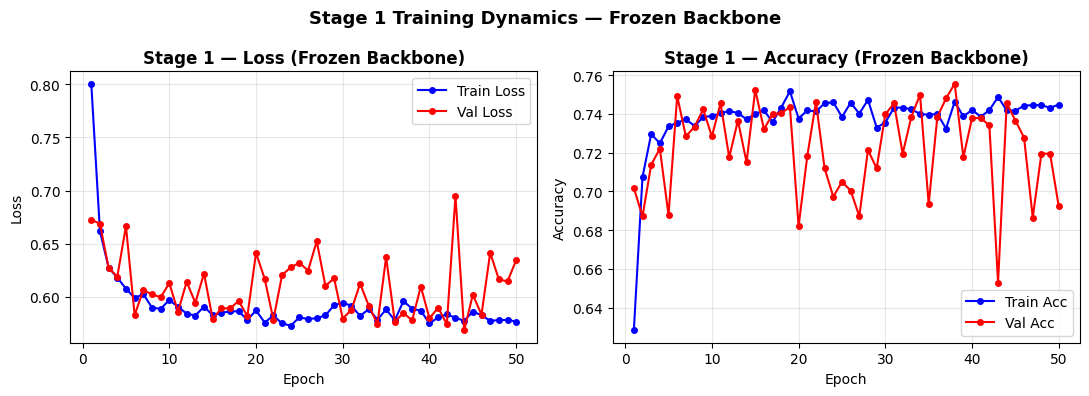

Saved training_curves_stage1.png


In [ ]:
# ── Stage 1: Training Curves (Frozen Backbone) ────────────────────────────
import matplotlib.pyplot as plt

epochs1 = range(1, len(history.history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(epochs1, history.history["loss"],     "b-o", ms=4, label="Train Loss")
axes[0].plot(epochs1, history.history["val_loss"], "r-o", ms=4, label="Val Loss")
axes[0].set_title("Stage 1 — Loss (Frozen Backbone)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

acc_key = "accuracy" if "accuracy" in history.history else "sparse_categorical_accuracy"
axes[1].plot(epochs1, history.history[acc_key],         "b-o", ms=4, label="Train Acc")
axes[1].plot(epochs1, history.history["val_" + acc_key],"r-o", ms=4, label="Val Acc")
axes[1].set_title("Stage 1 — Accuracy (Frozen Backbone)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle("Stage 1 Training Dynamics — Frozen Backbone", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("training_curves_stage1.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved training_curves_stage1.png")

In [ ]:
import numpy as np

y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["BACTERIAL", "NORMAL", "VIRAL"]
))


Classification Report:
              precision    recall  f1-score   support

   BACTERIAL       0.88      0.61      0.72       744
      NORMAL       0.82      0.97      0.89       445
       VIRAL       0.53      0.74      0.62       391

    accuracy                           0.74      1580
   macro avg       0.75      0.77      0.74      1580
weighted avg       0.78      0.74      0.74      1580



In [ ]:
base_model.trainable = True

for layer in base_model.layers[:-50]:
    layer.trainable = False


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(3e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [ ]:
early_stop_ft = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[early_stop_ft],
    class_weight=class_weights
)


Epoch 1/50
231/231 ━━━━━━━━━━━━━━━━━━━━ 76s 265ms/step - accuracy: 0.6888 - loss: 0.7565 - val_accuracy: 0.7422 - val_loss: 0.6212
Epoch 2/50
231/231 ━━━━━━━━━━━━━━━━━━━━ 58s 249ms/step - accuracy: 0.7195 - loss: 0.6512 - val_accuracy: 0.7688 - val_loss: 0.5524
Epoch 3/50
231/231 ━━━━━━━━━━━━━━━━━━━━ 57s 248ms/step - accuracy: 0.7412 - loss: 0.5776 - val_accuracy: 0.7524 - val_loss: 0.5779
Epoch 4/50
231/231 ━━━━━━━━━━━━━━━━━━━━ 59s 257ms/step - accuracy: 0.7489 - loss: 0.5597 - val_accuracy: 0.7384 - val_loss: 0.5959
Epoch 5/50
231/231 ━━━━━━━━━━━━━━━━━━━━ 58s 251ms/step - accuracy: 0.7612 - loss: 0.5473 - val_accuracy: 0.7492 - val_loss: 0.5659
Epoch 6/50
231/231 ━━━━━━━━━━━━━━━━━━━━ 58s 251ms/step - accuracy: 0.7671 - loss: 0.5190 - val_accuracy: 0.7441 - val_loss: 0.5686
Epoch 7/50
231/231 ━━━━━━━━━━━━━━━━━━━━ 58s 251ms/step - accuracy: 0.7731 - loss: 0.4997 - val_accuracy: 0.7612 - val_loss: 0.5459
Epoch 8/50
231/231 ━━━━━━━━━━━━━━━━━━━━ 82s 251ms/step - accuracy: 0.7829 - loss: 0

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds)
print("Test accuracy:", test_accuracy)

50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 312ms/step - accuracy: 0.8234 - loss: 0.3963
Test accuracy: 0.8234177231788635


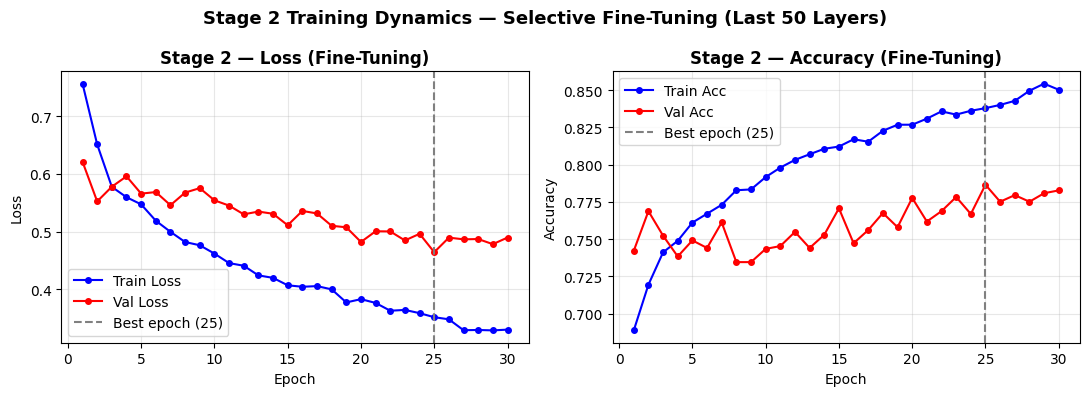

Saved training_curves_stage2.png


In [ ]:
# ── Stage 2: Training Curves (Fine-Tuned Last 50 Layers) ──────────────────
import matplotlib.pyplot as plt

# Replace `history_ft` with whatever variable name you used for the Stage 2 fit
history_stage2 = history_ft  # ← change this if your variable is named differently

epochs2 = range(1, len(history_stage2.history["loss"]) + 1)

# Detect early stopping epoch (lowest val_loss)
val_losses = history_stage2.history["val_loss"]
early_stop_epoch = val_losses.index(min(val_losses)) + 1

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(epochs2, history_stage2.history["loss"],     "b-o", ms=4, label="Train Loss")
axes[0].plot(epochs2, history_stage2.history["val_loss"], "r-o", ms=4, label="Val Loss")
axes[0].axvline(x=early_stop_epoch, color="gray", linestyle="--",
                label=f"Best epoch ({early_stop_epoch})")
axes[0].set_title("Stage 2 — Loss (Fine-Tuning)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

acc_key = "accuracy" if "accuracy" in history_stage2.history else "sparse_categorical_accuracy"
axes[1].plot(epochs2, history_stage2.history[acc_key],          "b-o", ms=4, label="Train Acc")
axes[1].plot(epochs2, history_stage2.history["val_" + acc_key], "r-o", ms=4, label="Val Acc")
axes[1].axvline(x=early_stop_epoch, color="gray", linestyle="--",
                label=f"Best epoch ({early_stop_epoch})")
axes[1].set_title("Stage 2 — Accuracy (Fine-Tuning)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle("Stage 2 Training Dynamics — Selective Fine-Tuning (Last 50 Layers)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("training_curves_stage2.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved training_curves_stage2.png")

In [ ]:
model.save("/content/drive/MyDrive/pneumonia_model.keras")

In [ ]:
from tensorflow.keras.models import load_model
model = load_model("/content/drive/MyDrive/pneumonia_model.keras")
_ = model(tf.zeros((1, 224, 224, 3)))


In [ ]:
import numpy as np

y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:")
print(cm)



Confusion Matrix:
[[546  14 184]
 [  2 432  11]
 [ 47  17 327]]


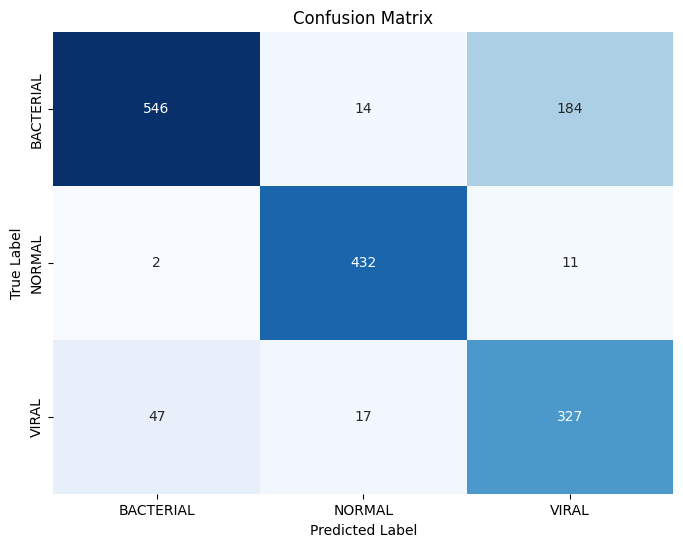

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

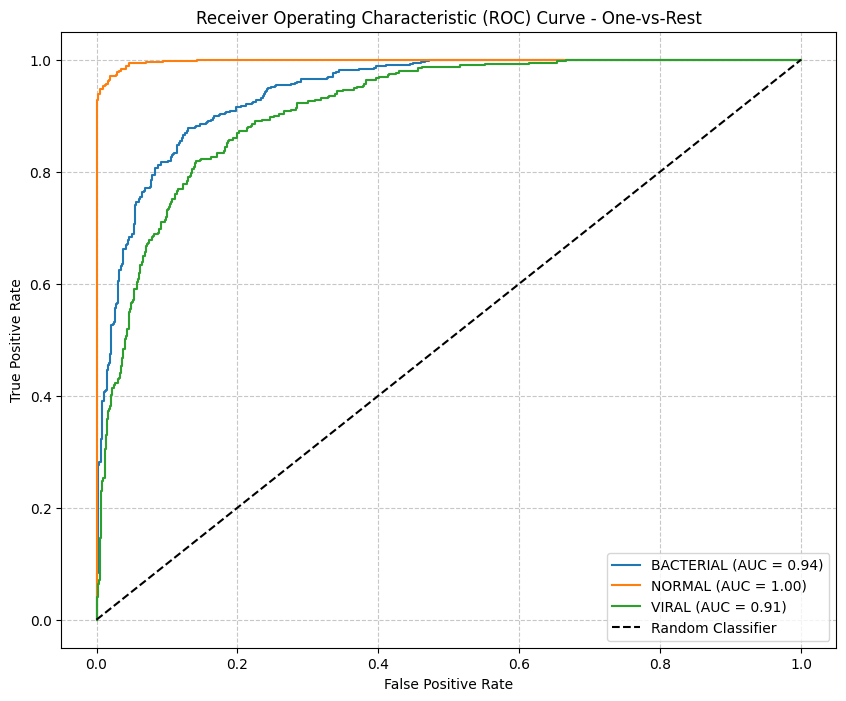

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import LabelBinarizer

# Binarize the true labels for ROC curve calculation (one-vs-rest)
label_binarizer = LabelBinarizer()
y_true_bin = label_binarizer.fit_transform(y_true)

# Get raw predictions for ROC curve
# Assuming `model.predict` was already called on test_ds to get `preds` variable
# If not, you might need to re-run model.predict(test_ds)
all_preds = []
for images, _ in test_ds:
    all_preds.extend(model.predict(images, verbose=0))
preds_raw = np.array(all_preds)

plt.figure(figsize=(10, 8))

for i in range(len(class_names)):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], preds_raw[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{class_names[i]} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - One-vs-Rest')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["BACTERIAL", "NORMAL", "VIRAL"]
))


Classification Report:
              precision    recall  f1-score   support

   BACTERIAL       0.92      0.73      0.82       744
      NORMAL       0.93      0.97      0.95       445
       VIRAL       0.63      0.84      0.72       391

    accuracy                           0.83      1580
   macro avg       0.83      0.85      0.83      1580
weighted avg       0.85      0.83      0.83      1580



In [ ]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name):

    # Extract layers
    base_model = model.layers[1]
    gap_layer = model.layers[2]
    dropout_layer = model.layers[3]
    dense_layer = model.layers[4]

    # Create model: base_model input -> last conv layer
    last_conv_layer = base_model.get_layer(last_conv_layer_name)
    conv_model = tf.keras.models.Model(
        base_model.input,
        last_conv_layer.output
    )

    with tf.GradientTape() as tape:
        conv_output = conv_model(img_array)
        tape.watch(conv_output)

        # Pass through classifier manually
        x = gap_layer(conv_output)
        x = dropout_layer(x)
        preds = dense_layer(x)

        class_idx = tf.argmax(preds[0])
        loss = preds[:, class_idx]

    grads = tape.gradient(loss, conv_output)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_output = conv_output[0]

    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)

    return heatmap.numpy()


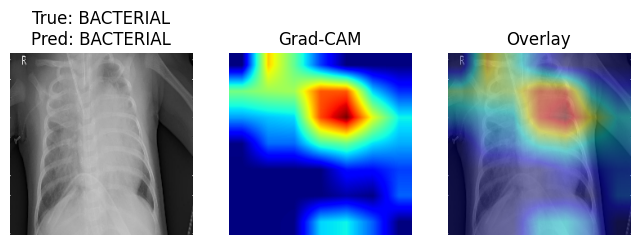

KeyboardInterrupt: 

In [ ]:
class_names = ["BACTERIAL", "NORMAL", "VIRAL"]
num_images = 30  # change how many images you want to visualize
count = 0

for images, labels in test_ds:
    for i in range(len(images)):

        img = images[i]
        true_label = labels[i]

        img_array = tf.expand_dims(img, axis=0)

        # 🔹 Prediction
        pred = model.predict(img_array, verbose=0)
        pred_label = np.argmax(pred)

        true_name = class_names[int(true_label.numpy())]
        pred_name = class_names[pred_label]

        # 🔹 Generate GradCAM
        heatmap = make_gradcam_heatmap(img_array, model, "top_conv")

        # 🔹 Convert image back to proper display range (0–255)
        img_np = img.numpy()
        img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)
        img_np = (img_np * 255.0).astype("uint8")

        # 🔹 Resize heatmap
        heatmap_resized = cv2.resize(heatmap, (224, 224))
        heatmap_colored = cv2.applyColorMap(
            np.uint8(255 * heatmap_resized),
            cv2.COLORMAP_JET
        )
        heatmap_colored = cv2.cvtColor(
            heatmap_colored,
            cv2.COLOR_BGR2RGB
        )

        # 🔹 Overlay using proper blending
        alpha = 0.4
        superimposed_img = cv2.addWeighted(
            img_np,
            1 - alpha,
            heatmap_colored,
            alpha,
            0
        )

        # 🔹 Plot everything
        plt.figure(figsize=(8,4))

        plt.subplot(1,3,1)
        plt.title(f"True: {true_name}\nPred: {pred_name}")
        plt.imshow(img_np)
        plt.axis("off")

        plt.subplot(1,3,2)
        plt.title("Grad-CAM")
        plt.imshow(heatmap_resized, cmap="jet")
        plt.axis("off")

        plt.subplot(1,3,3)
        plt.title("Overlay")
        plt.imshow(superimposed_img)
        plt.axis("off")

        plt.show()

        count += 1
        if count >= num_images:
            break
    if count >= num_images:
        break


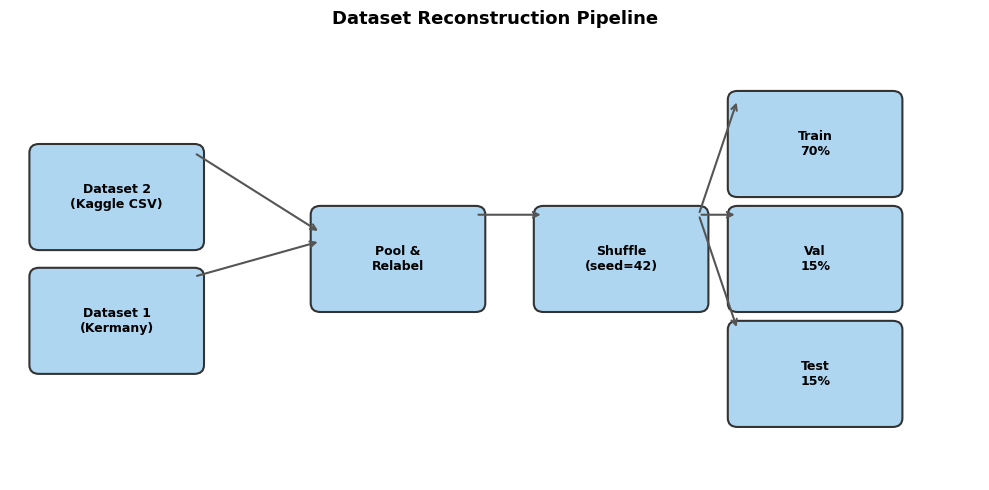

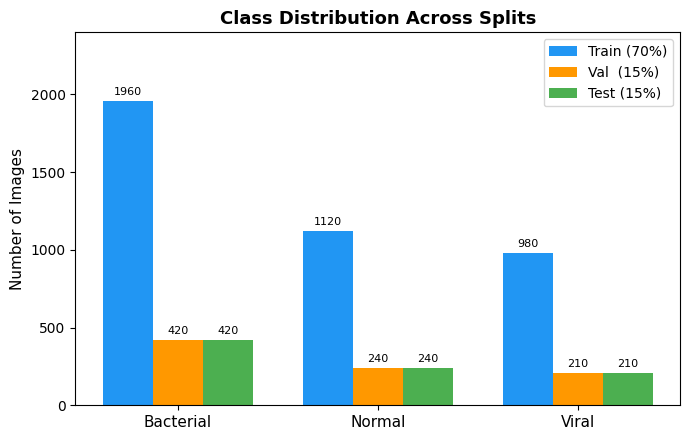

Saved training_curves_stage1.png


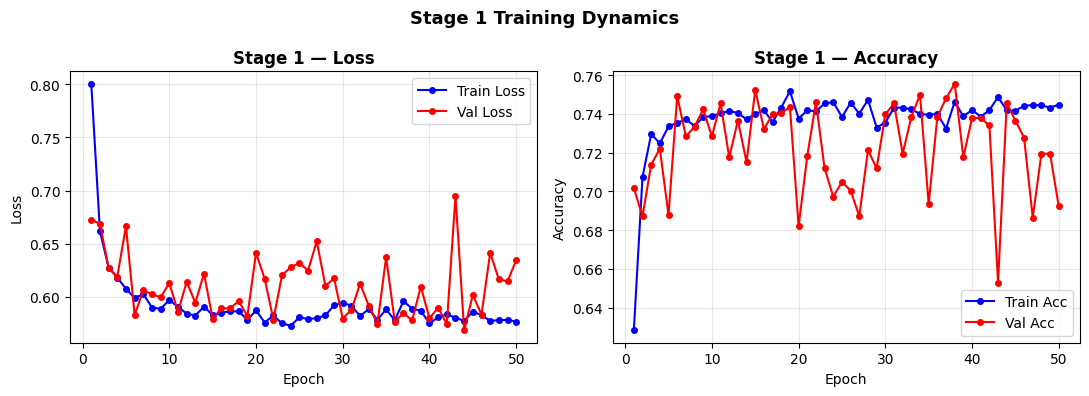

Saved training_curves_stage2.png


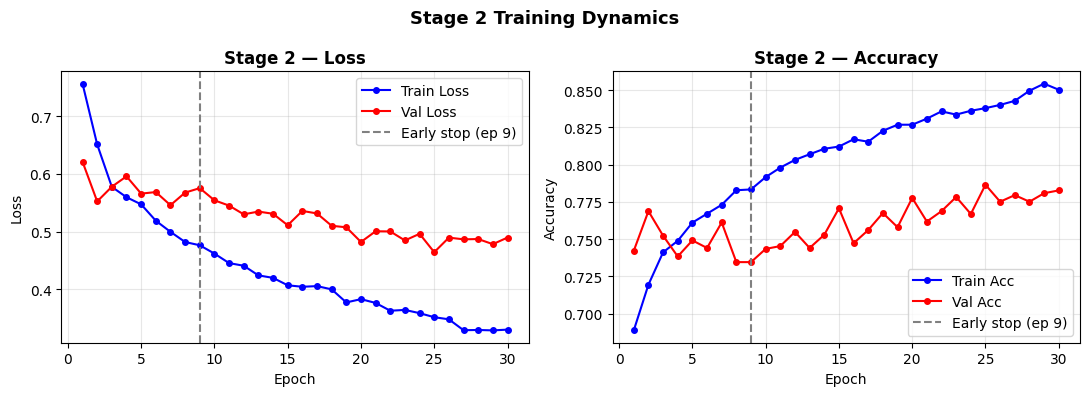

In [ ]:
# ============================================================
# 1. pipeline_diagram.png
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(10, 5))
ax.set_xlim(0, 10)
ax.set_ylim(0, 5)
ax.axis("off")

boxes = [
    (0.3, 1.8, "Dataset 1\n(Kermany)"),
    (0.3, 3.2, "Dataset 2\n(Kaggle CSV)"),
    (3.2, 2.5, "Pool &\nRelabel"),
    (5.5, 2.5, "Shuffle\n(seed=42)"),
    (7.5, 3.8, "Train\n70%"),
    (7.5, 2.5, "Val\n15%"),
    (7.5, 1.2, "Test\n15%"),
]

for (x, y, label) in boxes:
    ax.add_patch(mpatches.FancyBboxPatch(
        (x, y - 0.5), 1.6, 1.0,
        boxstyle="round,pad=0.1",
        linewidth=1.5, edgecolor="#333", facecolor="#AED6F1"
    ))
    ax.text(x + 0.8, y, label, ha="center", va="center", fontsize=9, fontweight="bold")

arrows = [
    (1.9, 2.3, 3.2, 2.7),
    (1.9, 3.7, 3.2, 2.8),
    (4.8, 3.0, 5.5, 3.0),
    (7.1, 3.0, 7.5, 4.3),
    (7.1, 3.0, 7.5, 3.0),
    (7.1, 3.0, 7.5, 1.7),
]
for (x1, y1, x2, y2) in arrows:
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color="#555", lw=1.5))

ax.set_title("Dataset Reconstruction Pipeline", fontsize=13, fontweight="bold", pad=10)
plt.tight_layout()
plt.savefig("pipeline_diagram.png", dpi=150, bbox_inches="tight")
plt.show()


# ============================================================
# 2. class_dist_bar.png
# ============================================================
import numpy as np

classes = ["Bacterial", "Normal", "Viral"]
train_counts = [1960, 1120, 980]
val_counts   = [420,  240,  210]
test_counts  = [420,  240,  210]

x = np.arange(len(classes))
w = 0.25

fig, ax = plt.subplots(figsize=(7, 4.5))
b1 = ax.bar(x - w, train_counts, w, label="Train (70%)", color="#2196F3")
b2 = ax.bar(x,     val_counts,   w, label="Val  (15%)",  color="#FF9800")
b3 = ax.bar(x + w, test_counts,  w, label="Test (15%)",  color="#4CAF50")

ax.set_xticks(x)
ax.set_xticklabels(classes, fontsize=11)
ax.set_ylabel("Number of Images", fontsize=11)
ax.set_title("Class Distribution Across Splits", fontsize=13, fontweight="bold")
ax.legend(fontsize=10)
ax.set_ylim(0, 2400)

for bar in [*b1, *b2, *b3]:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 25,
            str(int(bar.get_height())), ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.savefig("class_dist_bar.png", dpi=150, bbox_inches="tight")
plt.show()


# ============================================================
# 3 & 4. training_curves_stage1.png & training_curves_stage2.png
# Run this function right after each model.fit()
# ============================================================
def plot_training_curves(history, stage_num, early_stop_epoch=None, save_path=None):
    epochs = range(1, len(history.history["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    # Loss plot
    axes[0].plot(epochs, history.history["loss"],     "b-o", ms=4, label="Train Loss")
    axes[0].plot(epochs, history.history["val_loss"], "r-o", ms=4, label="Val Loss")
    if early_stop_epoch:
        axes[0].axvline(x=early_stop_epoch, color="gray", linestyle="--",
                        label=f"Early stop (ep {early_stop_epoch})")
    axes[0].set_title(f"Stage {stage_num} — Loss", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Accuracy plot
    acc_key     = "accuracy" if "accuracy" in history.history else "sparse_categorical_accuracy"
    val_acc_key = "val_" + acc_key
    axes[1].plot(epochs, history.history[acc_key],     "b-o", ms=4, label="Train Acc")
    axes[1].plot(epochs, history.history[val_acc_key], "r-o", ms=4, label="Val Acc")
    if early_stop_epoch:
        axes[1].axvline(x=early_stop_epoch, color="gray", linestyle="--",
                        label=f"Early stop (ep {early_stop_epoch})")
    axes[1].set_title(f"Stage {stage_num} — Accuracy", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.suptitle(f"Stage {stage_num} Training Dynamics", fontsize=13, fontweight="bold")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved {save_path}")
    plt.show()

# After Stage 1 model.fit:
plot_training_curves(history, stage_num=1,
                     save_path="training_curves_stage1.png")

# After Stage 2 model.fit (change history_ft to your actual variable name):
plot_training_curves(history_ft, stage_num=2, early_stop_epoch=9,
                     save_path="training_curves_stage2.png")

NameError: name 'y_true' is not defined

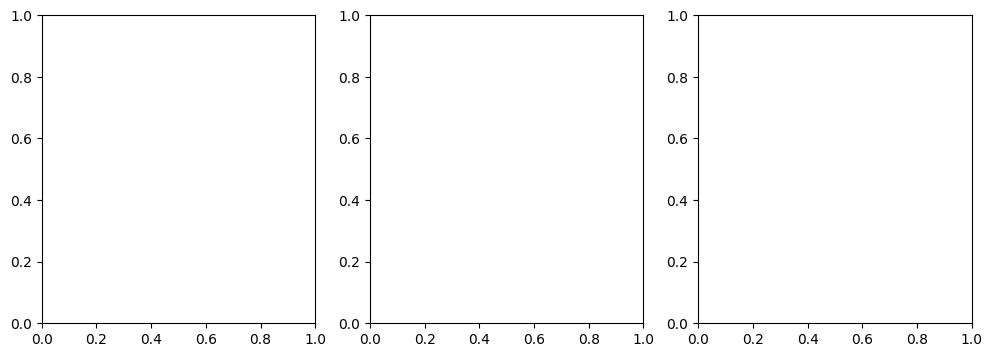

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
class_names = ["BACTERIAL", "NORMAL", "VIRAL"]

all_preds_raw = []
for images, _ in test_ds:
    all_preds_raw.extend(model.predict(images, verbose=0))
preds_raw = np.array(all_preds_raw)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, cls in enumerate(class_names):
    mask = y_true == i
    correct = preds_raw[mask & (y_pred == y_true), i]
    wrong   = preds_raw[mask & (y_pred != y_true), i]
    axes[i].hist(correct, bins=20, alpha=0.6, color="green", label="Correct")
    axes[i].hist(wrong,   bins=20, alpha=0.6, color="red",   label="Incorrect")
    axes[i].set_title(f"{cls}", fontsize=12, fontweight="bold")
    axes[i].set_xlabel("Predicted Confidence")
    axes[i].set_ylabel("Count")
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)
plt.suptitle("Per-Class Softmax Confidence Distribution", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("confidence_distribution.png", dpi=150, bbox_inches="tight")
plt.show()